## Exposure Simulation and CVA

In [1]:
from oreABBR import *; import ORE as oe; import oreUTIL as ou
params  = oe.Parameters()  ; params.fromFile("Input/ore.xml")
mainOBJ = oe.OREApp(params); mainOBJ.run() ;ou.chkERR(mainOBJ)
asofDT = mainOBJ.getInputs().asof() ; print('asof:',asofDT)
mainOBJ.getReportNames()

Run time:0.03 sec, Errors:0
asof: August 19th, 2022


('colva_nettingset_CPTY-An',
 'curves',
 'cva_sensitivity_nettingset_CPTY-An',
 'dividends',
 'exposure_nettingset_CPTY-An',
 'exposure_trade_OIS-2y',
 'fixings',
 'marketdata',
 'netcube',
 'npv',
 'pricingstats',
 'rawcube',
 'runtimes',
 'todaysmarketcalibration',
 'todaysmarketcalibration_cashflows',
 'xva')

,ID,nDate,nSamp,nDpth,val
0,0,0,0,0,"-230,413.27"
1,0,1,0,0,"-257,715.70"
2,0,1,1,0,"-20,887.83"
3,0,1,2,0,"-301,141.94"
4,0,2,0,0,"27,613.96"
5,0,2,1,0,"-406,988.16"
6,0,2,2,0,"19,335.14"
7,0,3,0,0,"99,002.80"
8,0,3,1,0,"-344,532.97"
9,0,3,2,0,"-6,183.62"


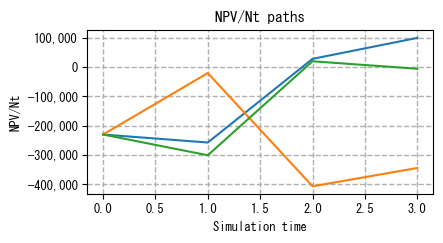

In [2]:
# (数値の確認用) cube gzip読み込みとグラフ
dfCB = pd.read_csv('Output/cube.csv.gz',comment='#',header=None)
dfCB.columns  = ['ID','nDate','nSamp','nDpth','val']; dfSTL(dfCB, fmO)
# NPV/Nt path plot
val0 = dfCB.val.iloc[0]; dfCB1 = dfCB[dfCB.nDate!=0]; _,ax = plt.subplots()
for ss in dfCB1.nSamp.unique()[:10]:
	dfPT = dfCB1[dfCB1.nSamp == ss]
	ax.plot(np.r_[0, dfPT.nDate], np.r_[val0, dfPT.val])
ax.set(xlabel='Simulation time', ylabel='NPV/Nt') ; ax.set_title('NPV/Nt paths')
yFlt(ax,0); gdShow(ax)

**dfEPの内容について**  
* Date列は図4.17のsiDTと同じ
* Time列はActualActual(ISDA)で算出されているため、図4.17 のsiYRとは値が異なる

In [3]:
expOBJ= mainOBJ.getReport("exposure_trade_OIS-2y")
dfEP  = ou.rOBJxdf(expOBJ); print('dfEP: 行列',dfEP.shape); dfSTLT(dfEP,fmE)

dfEP: 行列 (4, 12)


,0,1,2,3
TradeId,OIS-2y,OIS-2y,OIS-2y,OIS-2y
Date,2022-08-19,2023-02-20,2023-08-21,2024-02-19
Time,0.000000,0.506849,1.005479,1.503743
EPE,0.00,0.00,"15,649.70","33,000.93"
ENE,"230,413.27","193,248.48","135,662.72","116,905.53"
AllocatedEPE,0.00,0.00,0.00,0.00
AllocatedENE,0.00,0.00,0.00,0.00
PFE,0.00,0.00,"27,613.96","99,002.80"
BaselEE,0.00,0.00,"15,651.60","33,016.07"
BaselEEE,0.00,0.00,"15,651.60","33,016.07"


**dfEP.style.format(fmE) の復習**  
* dfEP.style: dfEP という DataFrame から Styler オブジェクトを取得
* dfEP.style.format(fmE): Styler オブジェクトに対し、.format(fmE)メソッドで表示形式を設定
* dfSTLT関数では styOB.format(fmt, **subset=pd.IndexSlice[col, :]**) という引数を追加し、行単位でスタイルを適応させている

- 列名を変数で指定する場合, []を使う (ドット演算はエラー)

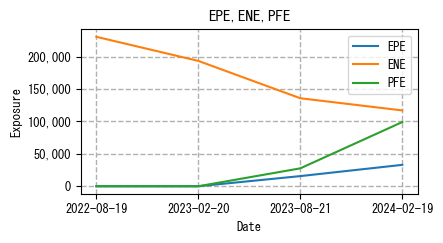

In [6]:
_,ax = plt.subplots()
colLST = ['EPE','ENE','PFE']
for ss in colLST: ax.plot(dfEP.Date, dfEP[ss], label=ss)
ax.set(xlabel='Date', ylabel='Exposure') ; ax.set_title('EPE,ENE,PFE')
yFlt(ax,0); lgD(ax); gdShow(ax)

**生存確率**

In [7]:
yrFeb2024 = yrF(dcA365,jDT(2022,8,19),jDT(2024,2,19));print(yrFeb2024)
np.exp(-0.01*yrFeb2024)

1.5041095890410958


0.9850714563826029

**CVA数値例**

In [9]:
xvaOBJ = mainOBJ.getReport("xva"); dfXV = ou.rOBJxdf(xvaOBJ)
print('dfXV: 行列',dfXV.shape)       ; dfSTLT(dfXV,fmX)

dfXV: 行列 (2, 22)


,0,1
TradeId,,OIS-2y
NettingSetId,CPTY-An,CPTY-An
CVA,155.97,155.97
DVA,"1,445.61","1,445.61"
FBA,0.00,0.00
FCA,0.00,0.00
FBAexOwnSP,0.00,0.00
FCAexOwnSP,0.00,0.00
FBAexAllSP,0.00,0.00
FCAexAllSP,0.00,0.00


In [10]:
necOBJ = mainOBJ.getReport("netcube")
dfNC  = ou.rOBJxdf(necOBJ); print('行,列:',dfNC.shape); display(dfNC)

行,列: (10, 7)


,Id,NettingSet,DateIndex,Date,Sample,Depth,Value
0,CPTY-An,,0,2022-08-19,0,0,-230413.265625
1,CPTY-An,,1,2023-02-20,1,0,-257715.703125
2,CPTY-An,,1,2023-02-20,2,0,-20887.826172
3,CPTY-An,,1,2023-02-20,3,0,-301141.937500
4,CPTY-An,,2,2023-08-21,1,0,27613.962891
5,CPTY-An,,2,2023-08-21,2,0,-406988.156250
6,CPTY-An,,2,2023-08-21,3,0,19335.142578
7,CPTY-An,,3,2024-02-19,1,0,99002.804688
8,CPTY-An,,3,2024-02-19,2,0,-344532.968750
9,CPTY-An,,3,2024-02-19,3,0,-6183.623047
